In [ ]:
# ----------------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# ----------------------------------------------------------------------------
import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from scipy import stats
from scipy.stats import norm, skew, spearmanr, qmc
from scipy.optimize import minimize
from scipy.spatial.distance import cdist
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# ----------------------------------------------------------------------------
# Figures Settings
# ----------------------------------------------------------------------------
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#e34948"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
X = np.load('..\Function_4_Data\Week_13_Data/F4_Week_13_inputs.npy')
y = np.load('..\Function_4_Data\Week_13_Data/F4_Week_13_outputs.npy')
n, d = X.shape
N_INITIAL = 30
W12 = n - 1                         # row 41: the week-12 query (newest reading)
best = int(np.argmax(y))
xb = X[best]
BEST = y[best]
PREV = int(np.argmax(y[:W12]))      # the best before the newest reading
dist = np.linalg.norm(X - xb, axis=1)
print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried); newest x = {np.round(X[W12], 6)}, y = {y[W12]:.6f}")
print(f"Best observed: row {best}, x = {np.round(xb, 6)}, y = {BEST:.6f}; previous best {y[PREV]:.6f} (row {PREV}); "
      f"gain {BEST - y[PREV]:+.4f} ({100 * (BEST / y[PREV] - 1):+.1f}%)")
print(f"Newest vs Previous best: dx = {np.round(X[W12] - X[PREV], 4)}")
assert best == W12, "the newest row is no longer the best; the labels below assume it is"


n = 42 (30 initial + 12 queried); newest x = [0.422604 0.367638 0.406408 0.426606], y = 0.642706
Best observed: row 41, x = [0.422604 0.367638 0.406408 0.426606], y = 0.642706; previous best 0.615945 (row 37); gain +0.0268 (+4.3%)
Newest vs Previous best: dx = [ 0.    -0.005  0.     0.   ]



raw y skew -0.12, range [-32.63, 0.643]


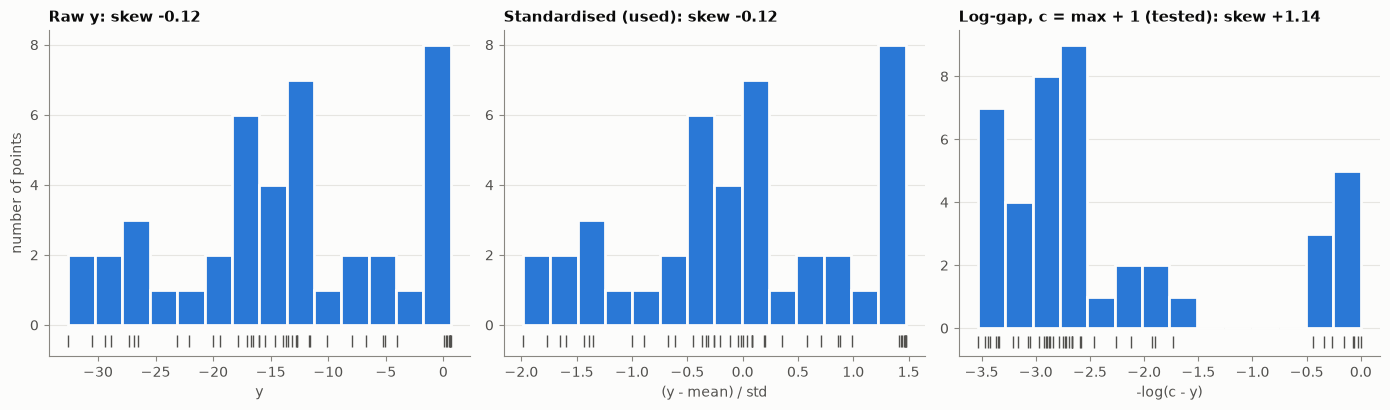

In [3]:
# ----------------------------------------------------------------------------
# 2. Data transformation + before/after plot
# ----------------------------------------------------------------------------

def t_std(v):
    return (v - v.mean()) / v.std(), lambda m: m * v.std() + v.mean()
def t_loggap(v, gap):
    c = v.max() + gap
    return -np.log(c - v), lambda m: c - np.exp(-m)
TRANSFORMS = {"standardised": t_std(y), "log-gap (c = max + 1)": t_loggap(y, 1.0),
              "log-gap (c = max + 0.3)": t_loggap(y, 0.3)}
print(f"\nraw y skew {skew(y):+.2f}, range [{y.min():.2f}, {y.max():.3f}]")

def fit(t, ard=True):
    k = (ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=[0.3] * d if ard else 1.0,
                                      length_scale_bounds=(1e-2, 1e1), nu=2.5)
         + WhiteKernel(1e-4, (1e-10, 1e-1)))
    return GaussianProcessRegressor(kernel=k, normalize_y=True, n_restarts_optimizer=20,
                                    random_state=SEED).fit(X, t)
# Fig 1: target distribution
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (title, v, xl) in zip(axes, [("Raw y", y, "y"),
                                     ("Standardised (used)", TRANSFORMS["standardised"][0], "(y - mean) / std"),
                                     ("Log-gap, c = max + 1 (tested)", TRANSFORMS["log-gap (c = max + 1)"][0], "-log(c - y)")]):
    ax.hist(v, bins=14, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.plot(v, np.full(n, -0.45), "|", color=INK2, markersize=9, clip_on=False)
    ax.set_title(f"{title}: skew {skew(v):+.2f}"); ax.set_xlabel(xl)
    ax.set_ylim(bottom=-0.9); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("number of points")
fig.tight_layout()


MODELS (LOO with hyperparameters fixed at the full fit)
  standardised, ARD                ls=[1.376 1.56  1.404 1.397]  noise sd (y)=0.179  LOO RMSE/std=0.147  Spearman=0.980  top-8 raw RMSE=0.233  top-8 Spearman=-0.57
  standardised, isotropic          ls=[1.383]  noise sd (y)=0.180  LOO RMSE/std=0.155  Spearman=0.980  top-8 raw RMSE=0.234  top-8 Spearman=-0.60


c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


  log-gap (c = max + 1), ARD       ls=[ 0.284 10.     0.347  0.396]  noise sd (y)=1.169  LOO RMSE/std=0.237  Spearman=0.835  top-8 raw RMSE=0.221  top-8 Spearman=-0.52


c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


  log-gap (c = max + 0.3), ARD     ls=[ 0.087 10.     0.204 10.   ]  noise sd (y)=1.703  LOO RMSE/std=0.326  Spearman=0.669  top-8 raw RMSE=0.193  top-8 Spearman=-0.14
  LOO prediction for the newest point (hyperparameters fixed): 0.410 +/- 0.199




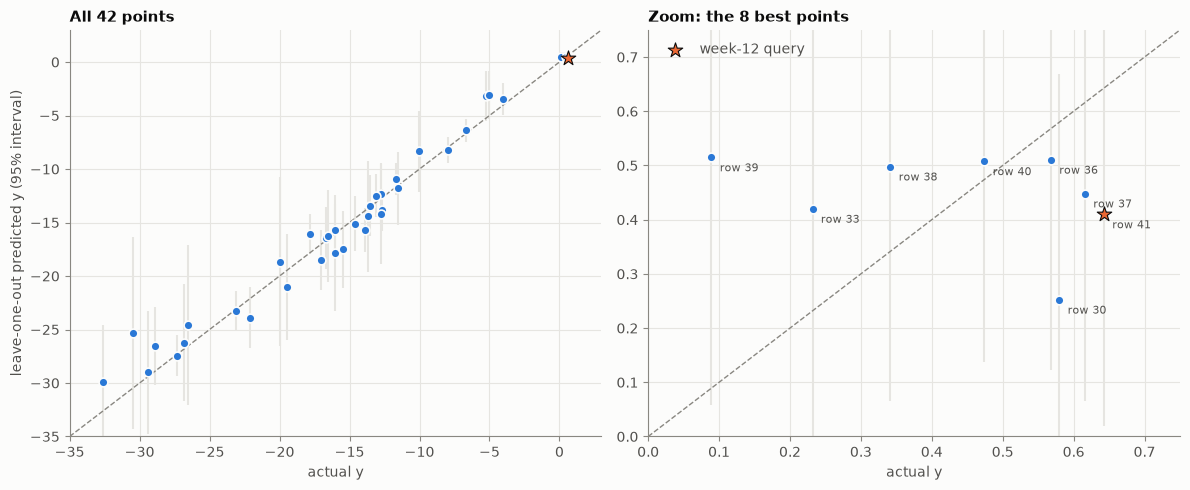

In [4]:
# ----------------------------------------------------------------------------
# 3. Surrogate: re-check isotropic vs ARD on all points
# ----------------------------------------------------------------------------

def loo(gp, t):
    mu, sd = np.empty(n), np.empty(n)
    for i in range(n):
        keep = np.arange(n) != i
        g = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None, normalize_y=True).fit(X[keep], t[keep])
        a, s = g.predict(X[i:i + 1], return_std=True)
        mu[i], sd[i] = a[0], s[0]
    return mu, sd

top = np.argsort(-y)[:8]
models, loos = {}, {}
print("\nMODELS (LOO with hyperparameters fixed at the full fit)")
for tname, (t, back) in TRANSFORMS.items():
    for ard in ((True, False) if tname == "standardised" else (True,)):
        key = f"{tname}, {'ARD' if ard else 'isotropic'}"
        gp_ = fit(t, ard)
        mu, sd = loo(gp_, t)
        models[key], loos[key] = (gp_, t, back), (mu, sd)
        yb = back(mu)
        ls = np.atleast_1d(gp_.kernel_.k1.k2.length_scale)
        print(f"  {key:32s} ls={np.round(ls, 3)}  noise sd (y)={np.sqrt(gp_.kernel_.k2.noise_level) * y.std():.3f}  "
              f"LOO RMSE/std={np.sqrt(np.mean((t - mu) ** 2)) / t.std():.3f}  Spearman={spearmanr(t, mu)[0]:.3f}  "
              f"top-8 raw RMSE={np.sqrt(np.mean((y[top] - yb[top]) ** 2)):.3f}  "
              f"top-8 Spearman={spearmanr(y[top], yb[top])[0]:+.2f}")
REC = "standardised, ARD"
gp, t, back = models[REC]
mu, sd = loos[REC]
print(f"  LOO prediction for the newest point (hyperparameters fixed): {back(mu)[W12]:.3f} +/- {sd[W12] * y.std():.3f}")
print('\n')

# Fig 2: LOO, full range and the top-8 zoom
yb, sb = back(mu), sd * y.std()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (lim, title) in zip(axes, [((-35, 3), f"All {n} points"), ((0.0, 0.75), "Zoom: the 8 best points")]):
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.errorbar(y, yb, yerr=1.96 * sb, fmt="none", ecolor=GRIDC, elinewidth=1.5, zorder=1)
    ax.scatter(y, yb, s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.scatter(y[W12], yb[W12], s=120, marker="*", color=ORANGE, edgecolor=INK, linewidth=0.8, zorder=4, label="week-12 query")
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("actual y"); ax.set_title(title)
axes[0].set_ylabel("leave-one-out predicted y (95% interval)")
axes[1].legend(frameon=False, loc="upper left", labelcolor=INK2)
for i in top:
    axes[1].annotate(f"row {i}", (y[i], yb[i]), xytext=(6, -10), textcoords="offset points", fontsize=8, color=INK2)
fig.tight_layout()

In [5]:
# ---------------------------------------------------------------- 
# y against x2 inside the slab
# ---------------------------------------------------------------- 

dx = X - xb
LOCAL = [i for i in np.argsort(dist) if dist[i] < 0.07]
SLAB = [i for i in LOCAL if abs(dx[i, 0]) <= 0.005]
OUTSIDE = [i for i in LOCAL if abs(dx[i, 0]) > 0.005]

u, v = X[SLAB, 1], y[SLAB]
order = np.argsort(u)
print(f"\nSLAB READINGS BY x2 (rows {list(np.array(SLAB)[order])}):")
for i in np.array(SLAB)[order]:
    print(f"  x2 = {X[i, 1]:.4f}  y = {y[i]:+.4f}  (row {i}; dx3 = {dx[i, 2]:+.3f}, dx4 = {dx[i, 3]:+.3f})")
b1, b0 = np.polyfit(u, v, 1)
res_ = v - (b0 + b1 * u); dof = len(u) - 2; sig = np.sqrt(res_ @ res_ / dof)
Sxx = np.sum((u - u.mean()) ** 2); se_b1 = sig / np.sqrt(Sxx)
rho, p_rho = spearmanr(u, v)
print(f"  linear fit y = {b0:.3f} + {b1:.2f} * x2: slope {b1:.2f} +/- {se_b1:.2f} (t = {b1 / se_b1:.2f}, {dof} dof), "
      f"residual sd {sig:.3f}; Spearman rho = {rho:+.2f} (p = {p_rho:.2f})")
q2 = np.polyfit(u, v, 2)
print(f"  quadratic fit: coefficient of x2^2 = {q2[0]:.0f} ({'convex: no interior maximum' if q2[0] > 0 else 'concave'}), vertex at x2 = {-q2[1] / (2 * q2[0]):.4f}")
rng = np.random.default_rng(0); conc = []
for _ in range(5000):
    ii = rng.integers(0, len(u), len(u))
    if len(set(u[ii])) < 3:
        continue
    qq = np.polyfit(u[ii], v[ii], 2); conc.append(qq[0] < 0)
print(f"  bootstrap: the quadratic is concave (has a maximum) in {100 * np.mean(conc):.0f}% of resamples")
slopes_pair = [(a, c) for a, c in zip(np.array(SLAB)[order][:-1], np.array(SLAB)[order][1:])]
print("  slopes between neighbouring x2 values: " + ", ".join(
    f"rows {a}-{c}: {(y[c] - y[a]) / (X[c, 1] - X[a, 1]):+.1f}" for a, c in slopes_pair))

# linear-regression predictive distribution along x2 (all other inputs at the best point)
A_ = np.column_stack([np.ones(len(u)), u]); cov_ = np.linalg.inv(A_.T @ A_)
def lin_pred(x2):
    h = np.array([1.0, x2]) @ cov_ @ np.array([1.0, x2])
    return b0 + b1 * x2, sig * np.sqrt(1 + h)
def lin_stats(x2):
    m, s = lin_pred(x2)
    z = (m - BEST) / s
    p = stats.t.sf(-z, dof)
    ei = s * (stats.t.pdf(z, dof) * (dof + z ** 2) / (dof - 1) + z * stats.t.cdf(z, dof))
    return m, s, p, ei


SLAB READINGS BY x2 (rows [np.int64(41), np.int64(37), np.int64(40), np.int64(30), np.int64(36)]):
  x2 = 0.3676  y = +0.6427  (row 41; dx3 = +0.000, dx4 = +0.000)
  x2 = 0.3726  y = +0.6159  (row 37; dx3 = +0.000, dx4 = +0.000)
  x2 = 0.3864  y = +0.4742  (row 40; dx3 = -0.014, dx4 = -0.005)
  x2 = 0.3908  y = +0.5798  (row 30; dx3 = -0.044, dx4 = -0.014)
  x2 = 0.3958  y = +0.5680  (row 36; dx3 = +0.001, dx4 = +0.000)
  linear fit y = 1.803 + -3.21 * x2: slope -3.21 +/- 2.46 (t = -1.30, 3 dof), residual sd 0.059; Spearman rho = -0.70 (p = 0.19)
  quadratic fit: coefficient of x2^2 = 475 (convex: no interior maximum), vertex at x2 = 0.3847
  bootstrap: the quadratic is concave (has a maximum) in 16% of resamples
  slopes between neighbouring x2 values: rows 41-37: -5.4, rows 37-40: -10.3, rows 40-30: +23.9, rows 30-36: -2.4


In [6]:
# ---------------------------------------------------------------- 
# Candidates
# ---------------------------------------------------------------- 

S = qmc.Sobol(d, seed=1).random(2 ** 14)
lo, hi = np.clip(xb - 0.12, 0, 1), np.clip(xb + 0.12, 0, 1)
Z = lo + S * (hi - lo)
x0 = Z[gp.predict(Z).argmax()]
x_pm = minimize(lambda q: -gp.predict(q[None])[0], x0, bounds=list(zip(lo, hi)), method="L-BFGS-B").x
def lowered(dlt):
    return xb + np.array([0.0, -dlt, 0.0, 0.0])
cands = {
    "A: highest GP mean (+/-0.12 box)": x_pm,
    "B: resubmit the best point": xb.copy(),
    "C: best point, x2 lowered by 0.005": lowered(0.005),
    "D: best point, x2 lowered by 0.010": lowered(0.010),
    "E: best point, x2 lowered by 0.015": lowered(0.015),
    "F: best point, x2 lowered by 0.020": lowered(0.020),
}
POOR = [i for i in OUTSIDE]
print("\nCANDIDATES: global-GP prediction (standardised, ARD) and the slab regression along x2 (other inputs at the best point)")
for name, xc in cands.items():
    preds = {k: v_[2](v_[0].predict(xc[None]))[0] for k, v_ in models.items()}
    m, s = gp.predict(xc[None], return_std=True)
    ml, sl, pl, el = lin_stats(xc[1]) if np.allclose(xc[[0, 2, 3]], xb[[0, 2, 3]]) else (np.nan,) * 4
    print(f"  {name:36s} x = ({', '.join(f'{q:.6f}' for q in xc)})  dist {np.linalg.norm(xc - xb):.3f}  "
          f"GP {back(m)[0]:.3f} +/- {s[0] * y.std():.3f}  "
          + "  ".join(f"{k.split(',')[0]}={v_:.3f}" for k, v_ in preds.items() if k != REC)
          + f"  | slab regression: {ml:.3f} +/- {sl:.3f}, P(beat) {pl:.2f}, EI {el:.4f}"
          + f"  | |dx1| = {abs(xc[0] - xb[0]):.4f}  nearest poor point {np.min(np.linalg.norm(X[POOR] - xc, axis=1)):.3f}")
print(f"  (the slab regression at the best point itself predicts {lin_pred(xb[1])[0]:.3f}, against the observed {BEST:.3f})")



CANDIDATES: global-GP prediction (standardised, ARD) and the slab regression along x2 (other inputs at the best point)
  A: highest GP mean (+/-0.12 box)     x = (0.414524, 0.397055, 0.406700, 0.413378)  dist 0.033  GP 0.544 +/- 0.204  standardised=0.533  log-gap (c = max + 1)=0.484  log-gap (c = max + 0.3)=0.506  | slab regression: nan +/- nan, P(beat) nan, EI nan  | |dx1| = 0.0081  nearest poor point 0.036
  B: resubmit the best point           x = (0.422604, 0.367638, 0.406408, 0.426606)  dist 0.000  GP 0.460 +/- 0.197  standardised=0.452  log-gap (c = max + 1)=0.471  log-gap (c = max + 0.3)=0.507  | slab regression: 0.624 +/- 0.075, P(beat) 0.41, EI 0.0328  | |dx1| = 0.0000  nearest poor point 0.025
  C: best point, x2 lowered by 0.005   x = (0.422604, 0.362638, 0.406408, 0.426606)  dist 0.005  GP 0.437 +/- 0.201  standardised=0.428  log-gap (c = max + 1)=0.471  log-gap (c = max + 0.3)=0.507  | slab regression: 0.640 +/- 0.081, P(beat) 0.49, EI 0.0438  | |dx1| = 0.0000  nearest po

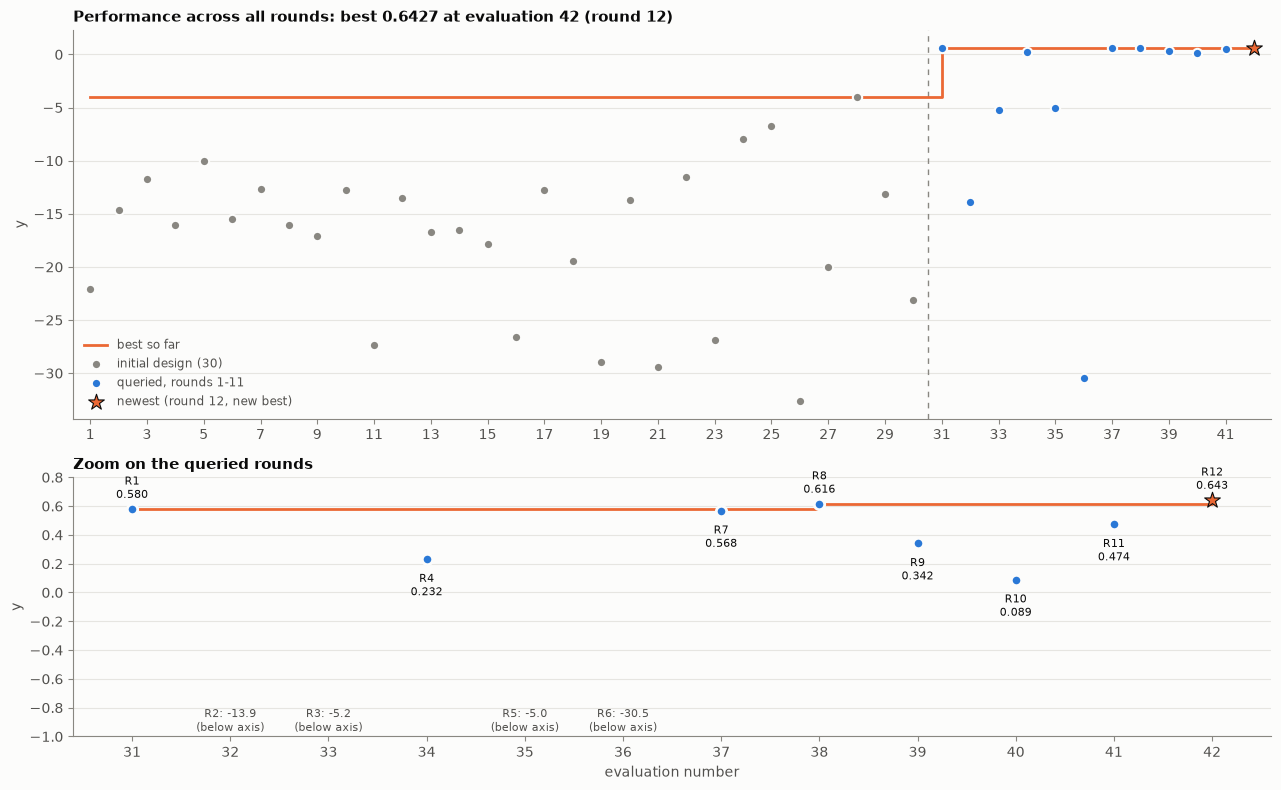

In [7]:
# Fig 1: performance across all rounds
idx = np.arange(1, n + 1)
bsf = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
fig, (ax, az) = plt.subplots(2, 1, figsize=(13, 8), height_ratios=[3, 2])
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, bsf, where="post", color=ORANGE, lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=45, color=MUTED, edgecolor=SURFACE, linewidth=1.5,
           label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:W12], y[N_INITIAL:W12], s=45, color=BLUE, edgecolor=SURFACE, linewidth=1.5,
           label=f"queried, rounds 1-{n - N_INITIAL - 1}", zorder=3)
ax.scatter(idx[W12], y[W12], s=140, marker="*", color=ORANGE, edgecolor=INK, linewidth=0.8, zorder=4,
           label=f"newest (round {n - N_INITIAL}, new best)")
ax.set_xticks(idx[::2]); ax.set_xlim(0.4, n + 0.6); ax.grid(axis="x", visible=False); ax.set_ylabel("y")
ax.set_title(f"Performance across all rounds: best {BEST:.4f} at evaluation {best + 1} (round {best - N_INITIAL + 1})")
ax.legend(frameon=False, loc="lower left", fontsize=8.5, labelcolor=INK2)
q = np.arange(N_INITIAL, n)
az.step(idx[q], bsf[q], where="post", color=ORANGE, lw=2, zorder=2)
for i in q:
    star = i == W12
    if y[i] >= -1:
        az.scatter(idx[i], y[i], s=140 if star else 56, marker="*" if star else "o", color=ORANGE if star else BLUE,
                   edgecolor=INK if star else SURFACE, linewidth=0.8 if star else 2, zorder=3)
        az.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.3f}", (idx[i], y[i]), xytext=(0, 8 if y[i] >= bsf[i] - 1e-12 else -26),
                    textcoords="offset points", ha="center", fontsize=8, color=INK)
    else:
        az.annotate(f"R{i - N_INITIAL + 1}: {y[i]:.1f}\n(below axis)", (idx[i], -1), xytext=(0, 4),
                    textcoords="offset points", ha="center", fontsize=8, color=INK2)
az.set_ylim(-1, 0.8); az.set_xticks(idx[q]); az.set_xlim(N_INITIAL + 0.4, n + 0.6)
az.grid(axis="x", visible=False); az.set_xlabel("evaluation number"); az.set_ylabel("y")
az.set_title("Zoom on the queried rounds")
fig.tight_layout()